<a href="https://colab.research.google.com/github/dtnguyen24174800190-sketch/dtnguyen-MLP/blob/main/btaptuan4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

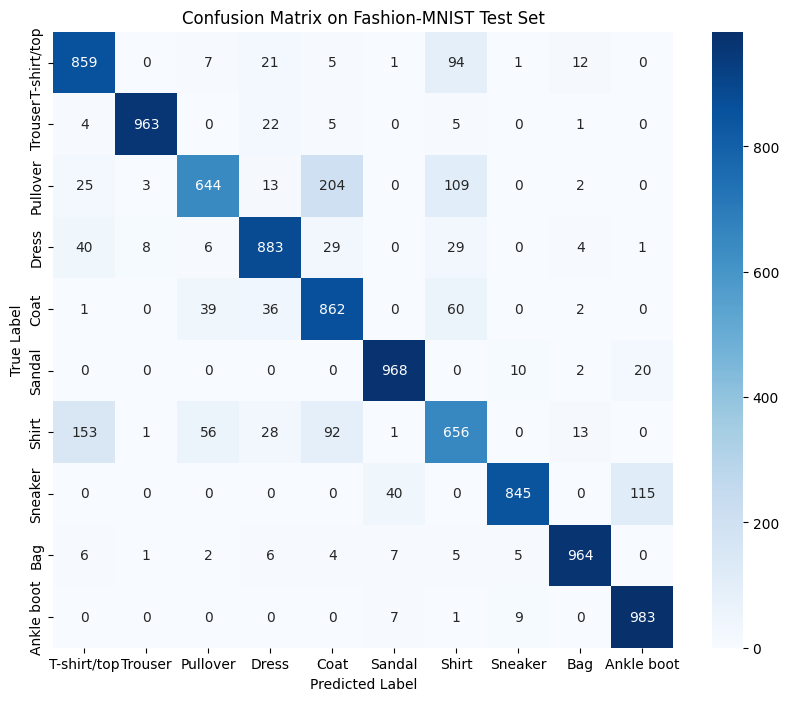

Cặp nhầm lẫn thứ 1: Thực tế là 'Pullover' nhưng bị đoán nhầm là 'Coat' (204 mẫu)
Cặp nhầm lẫn thứ 2: Thực tế là 'Shirt' nhưng bị đoán nhầm là 'T-shirt/top' (153 mẫu)


In [4]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Tính ma trận nhầm lẫn từ nhãn thực tế và nhãn dự đoán
cm = confusion_matrix(y_test, preds)

# Vẽ ma trận nhầm lẫn
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix on Fashion-MNIST Test Set')
plt.show()

# Tìm các cặp lớp bị nhầm lẫn nhiều nhất (loại trừ đường chéo chính)
cm_copy = cm.copy()
np.fill_diagonal(cm_copy, 0)

# Lấy top các cặp nhầm lẫn
flat_indices = np.argsort(-cm_copy.ravel())
for i in range(2):
    idx = flat_indices[i]
    true_cls, pred_cls = divmod(idx, len(class_names))
    print(f"Cặp nhầm lẫn thứ {i+1}: Thực tế là '{class_names[true_cls]}' nhưng bị đoán nhầm là '{class_names[pred_cls]}' ({cm_copy[true_cls, pred_cls]} mẫu)")

### Bài 1. Thay đổi kiến trúc
Chúng ta thử nghiệm với 3 cấu hình ẩn:
- 1 hidden layer: `[128]`
- 2 hidden layers: `[128, 64]`
- 3 hidden layers: `[256, 128, 64]`

In [5]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

# Khởi tạo dữ liệu chuẩn để đồng bộ các bài
(X_full, y_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
X_full = (X_full.astype("float32") / 255.0).reshape(-1, 28 * 28)
X_test = (X_test.astype("float32") / 255.0).reshape(-1, 28 * 28)
y_full = y_full.astype("int32")
y_test = y_test.astype("int32")

X_val, y_val = X_full[:10000], y_full[:10000]
X_train, y_train = X_full[10000:], y_full[10000:]

input_dim = X_train.shape[1]
num_classes = 10
SEED = 42

def train_model(hidden_units, lr=1e-3, batch_size=128, epochs=15, dropout=0.0, l2_val=0.0):
    tf.keras.backend.clear_session()
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    reg = regularizers.l2(l2_val) if l2_val > 0 else None
    model = models.Sequential([layers.Input(shape=(input_dim,))])
    for u in hidden_units:
        model.add(layers.Dense(u, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(num_classes, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    t0 = time.perf_counter()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        verbose=0
    )
    elapsed = time.perf_counter() - t0
    loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    val_acc = history.history['val_accuracy'][-1]

    return {
        'params': model.count_params(),
        'time': elapsed,
        'val_acc': val_acc,
        'test_acc': test_acc,
        'history': history.history
    }

# Chạy thử nghiệm Bài 1
results_b1 = {}
architectures = {
    "1 Hidden Layer [128]": [128],
    "2 Hidden Layers [128, 64]": [128, 64],
    "3 Hidden Layers [256, 128, 64]": [256, 128, 64]
}

print("=== BÀI 1: SO SÁNH KIẾN TRÚC ===")
for name, arch in architectures.items():
    res = train_model(arch, epochs=15)
    results_b1[name] = res
    print(f"{name:30s} | Params: {res['params']:6d} | Thời gian: {res['time']:.2f}s | Val Acc: {res['val_acc']:.4f} | Test Acc: {res['test_acc']:.4f}")

=== BÀI 1: SO SÁNH KIẾN TRÚC ===
1 Hidden Layer [128]           | Params: 101770 | Thời gian: 19.53s | Val Acc: 0.8866 | Test Acc: 0.8800
2 Hidden Layers [128, 64]      | Params: 109386 | Thời gian: 20.38s | Val Acc: 0.8837 | Test Acc: 0.8791
3 Hidden Layers [256, 128, 64] | Params: 242762 | Thời gian: 30.65s | Val Acc: 0.8846 | Test Acc: 0.8767


### Bài 2. Thử learning rate
Huấn luyện mô hình chuẩn `[128, 64]` với các giá trị: `1e-2`, `1e-3`, `1e-4` và vẽ Learning Curve.

=== BÀI 2: SO SÁNH LEARNING RATE ===
lr=1e-02 | Val Acc: 0.8640 | Test Acc: 0.8554
lr=1e-03 | Val Acc: 0.8786 | Test Acc: 0.8739
lr=1e-04 | Val Acc: 0.8757 | Test Acc: 0.8658


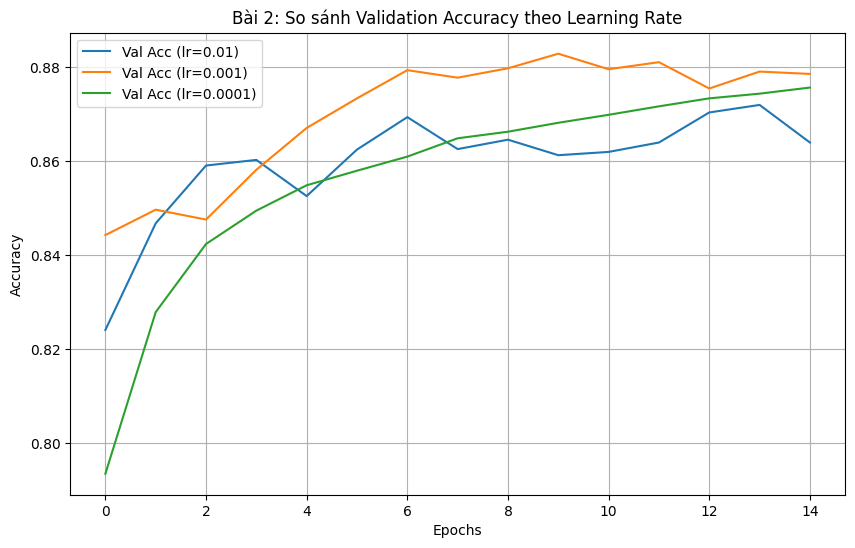

In [6]:
lrs = [1e-2, 1e-3, 1e-4]
results_b2 = {}

print("=== BÀI 2: SO SÁNH LEARNING RATE ===")
plt.figure(figsize=(10, 6))
for lr in lrs:
    res = train_model([128, 64], lr=lr, epochs=15)
    results_b2[lr] = res
    plt.plot(res['history']['val_accuracy'], label=f"Val Acc (lr={lr})")
    print(f"lr={lr:.0e} | Val Acc: {res['val_acc']:.4f} | Test Acc: {res['test_acc']:.4f}")

plt.title("Bài 2: So sánh Validation Accuracy theo Learning Rate")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

### Bài 3. Thử batch size
So sánh kích thước batch size: `32`, `128`, `512` sử dụng cấu hình chuẩn.

In [7]:
batch_sizes = [32, 128, 512]
results_b3 = {}

print("=== BÀI 3: SO SÁNH BATCH SIZE ===")
for bs in batch_sizes:
    res = train_model([128, 64], batch_size=bs, epochs=15)
    results_b3[bs] = res
    print(f"Batch size={bs:3d} | Thời gian train: {res['time']:.2f}s | Val Acc: {res['val_acc']:.4f} | Test Acc: {res['test_acc']:.4f}")

=== BÀI 3: SO SÁNH BATCH SIZE ===
Batch size= 32 | Thời gian train: 58.59s | Val Acc: 0.8869 | Test Acc: 0.8790
Batch size=128 | Thời gian train: 19.41s | Val Acc: 0.8869 | Test Acc: 0.8741
Batch size=512 | Thời gian train: 10.70s | Val Acc: 0.8733 | Test Acc: 0.8693


### Bài 4. Thêm Dropout
So sánh việc thêm lớp `Dropout(0.3)` sau mỗi lớp ẩn để xem mức độ hạn chế Overfitting.

=== BÀI 4: THỬ NGHIỆM DROPOUT(0.3) ===
Không Dropout | Train Acc: 0.9342 | Val Acc: 0.8908 | Test Acc: 0.8834
Có Dropout0.3 | Train Acc: 0.8908 | Val Acc: 0.8846 | Test Acc: 0.8793


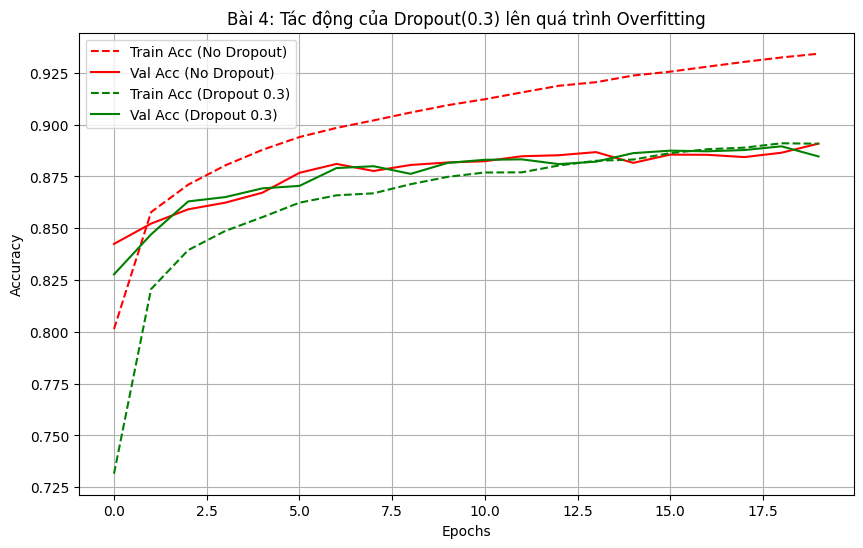

In [8]:
print("=== BÀI 4: THỬ NGHIỆM DROPOUT(0.3) ===")
no_dropout_res = train_model([128, 64], epochs=20, dropout=0.0)
dropout_res = train_model([128, 64], epochs=20, dropout=0.3)

print(f"Không Dropout | Train Acc: {no_dropout_res['history']['accuracy'][-1]:.4f} | Val Acc: {no_dropout_res['val_acc']:.4f} | Test Acc: {no_dropout_res['test_acc']:.4f}")
print(f"Có Dropout0.3 | Train Acc: {dropout_res['history']['accuracy'][-1]:.4f} | Val Acc: {dropout_res['val_acc']:.4f} | Test Acc: {dropout_res['test_acc']:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(no_dropout_res['history']['accuracy'], 'r--', label='Train Acc (No Dropout)')
plt.plot(no_dropout_res['history']['val_accuracy'], 'r-', label='Val Acc (No Dropout)')
plt.plot(dropout_res['history']['accuracy'], 'g--', label='Train Acc (Dropout 0.3)')
plt.plot(dropout_res['history']['val_accuracy'], 'g-', label='Val Acc (Dropout 0.3)')
plt.title("Bài 4: Tác động của Dropout(0.3) lên quá trình Overfitting")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

### Bài 5. Thêm L2 Regularization
Thử nghiệm áp dụng L2 regularization với giá trị `1e-4` vào mô hình.

In [9]:
print("=== BÀI 5: THỬ NGHIỆM L2 REGULARIZATION ===")
l2_res = train_model([128, 64], epochs=20, l2_val=1e-4)
print(f"Áp dụng L2 (1e-4) | Train Acc: {l2_res['history']['accuracy'][-1]:.4f} | Val Acc: {l2_res['val_acc']:.4f} | Test Acc: {l2_res['test_acc']:.4f}")

=== BÀI 5: THỬ NGHIỆM L2 REGULARIZATION ===
Áp dụng L2 (1e-4) | Train Acc: 0.9263 | Val Acc: 0.8801 | Test Acc: 0.8745


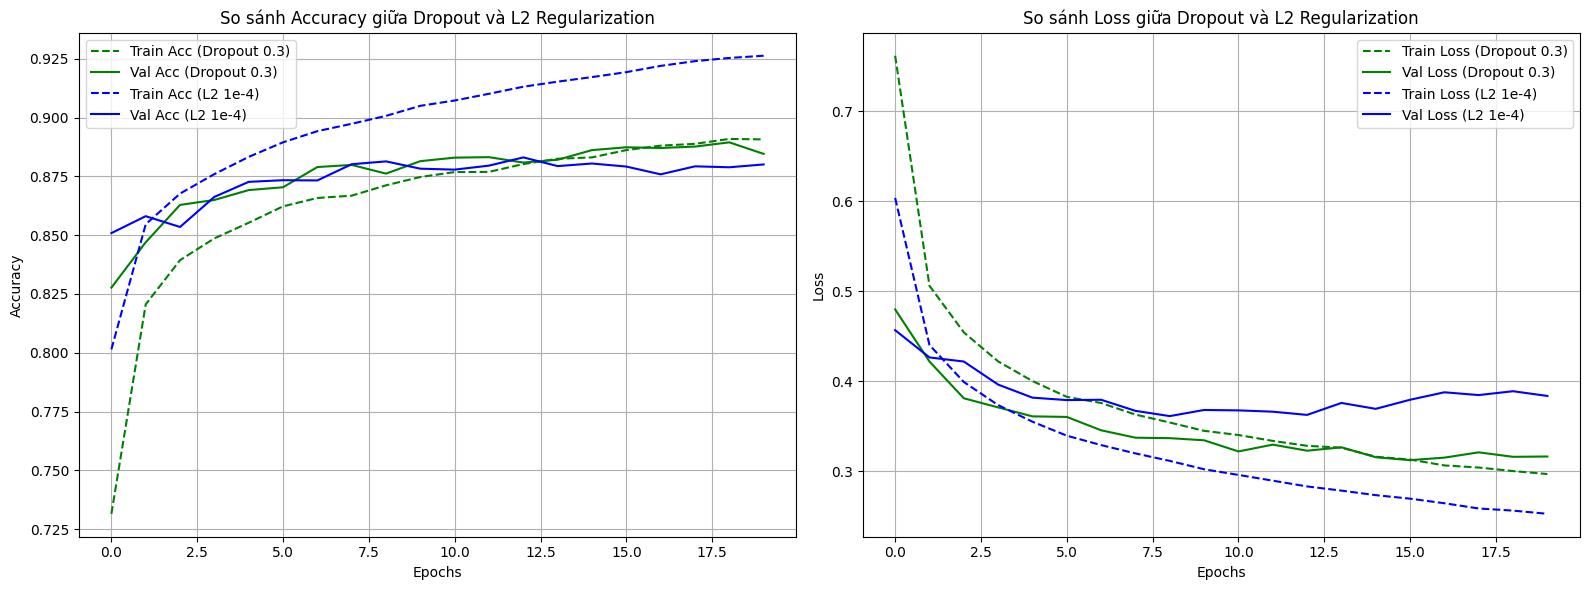

In [11]:
import matplotlib.pyplot as plt

# Thiết lập kích thước biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. So sánh Accuracy (Độ chính xác)
axes[0].plot(dropout_res['history']['accuracy'], 'g--', label='Train Acc (Dropout 0.3)')
axes[0].plot(dropout_res['history']['val_accuracy'], 'g-', label='Val Acc (Dropout 0.3)')
axes[0].plot(l2_res['history']['accuracy'], 'b--', label='Train Acc (L2 1e-4)')
axes[0].plot(l2_res['history']['val_accuracy'], 'b-', label='Val Acc (L2 1e-4)')
axes[0].set_title('So sánh Accuracy giữa Dropout và L2 Regularization')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# 2. So sánh Loss (Hàm mất mát)
axes[1].plot(dropout_res['history']['loss'], 'g--', label='Train Loss (Dropout 0.3)')
axes[1].plot(dropout_res['history']['val_loss'], 'g-', label='Val Loss (Dropout 0.3)')
axes[1].plot(l2_res['history']['loss'], 'b--', label='Train Loss (L2 1e-4)')
axes[1].plot(l2_res['history']['val_loss'], 'b-', label='Val Loss (L2 1e-4)')
axes[1].set_title('So sánh Loss giữa Dropout và L2 Regularization')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

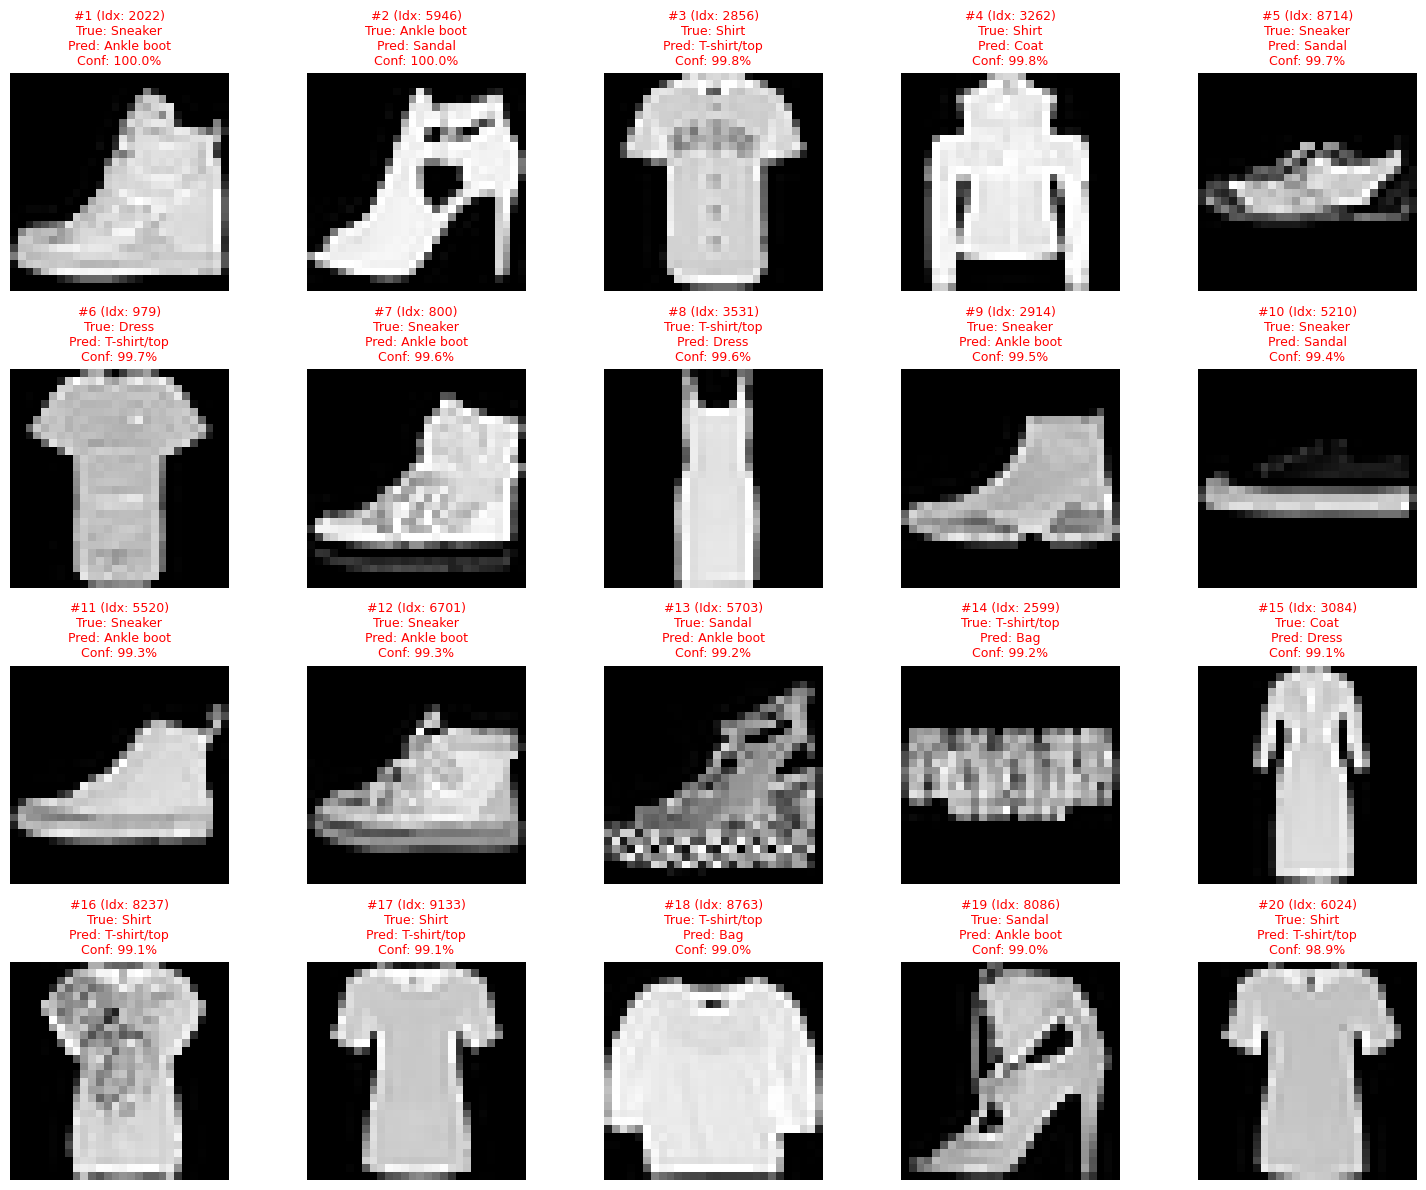

In [13]:
# Bài 6:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Kiểm tra nếu chưa chạy cell 13RRFC3Bip_P, chúng ta sẽ thực hiện khởi tạo và train nhanh
if 'top20_idx' not in globals() or 'preds' not in globals() or 'probs' not in globals():
    print("Đang thiết lập và chạy nhanh mô hình để lấy kết quả dự đoán...")
    # Thiết lập mô hình nhanh
    SEED = 42
    np.random.seed(SEED)
    tf.random.set_seed(SEED)
    (X_full, y_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
    X_test = (X_test.astype("float32") / 255.0).reshape(-1, 28 * 28)
    y_test = y_test.astype("int32")
    X_train = (X_full[10000:].astype("float32") / 255.0).reshape(-1, 28 * 28)
    y_train = y_full[10000:].astype("int32")

    model = tf.keras.models.Sequential([
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    model.fit(X_train, y_train, epochs=5, batch_size=128, verbose=0)

    probs = model.predict(X_test, verbose=0)
    preds = np.argmax(probs, axis=1)
    confs = np.max(probs, axis=1)
    wrong_idx = np.where(preds != y_test)[0]
    top20_idx = wrong_idx[np.argsort(-confs[wrong_idx])[:20]]

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

plt.figure(figsize=(15, 12))
for rank, idx in enumerate(top20_idx, 1):
    plt.subplot(4, 5, rank)
    img = X_test[idx].reshape(28, 28)
    plt.imshow(img, cmap='gray')

    true_label = class_names[y_test[idx]]
    pred_label = class_names[preds[idx]]
    conf_val = probs[idx, preds[idx]] * 100

    plt.title(f"#{rank} (Idx: {idx})\nTrue: {true_label}\nPred: {pred_label}\nConf: {conf_val:.1f}%", fontsize=9, color='red')
    plt.axis('off')

plt.tight_layout()
plt.show()